# CMiO: PCA-Geary permutation reference

**Goal.** Test whether the PCA components contributing to SC-PaCMAP's Geary-based spatial strength show stronger positive spatial continuity than expected after spatial randomization. This is a validation diagnostic only; the current SC-PaCMAP algorithm and benchmark embeddings are not changed.

## 1. Setup and exact analysis path

The notebook uses the same standardized feature representation, the PaCMAP preprocessing branch used for these $P\le100$ datasets, the same raw-coordinate neighborhood size $k=10$, and the same directed-kNN Geary formula as the supplied SC-PaCMAP code. Exact Euclidean kNN is used for the diagnostic to avoid approximate-search variability.

In [1]:

from __future__ import annotations
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

N_NEIGHBORS = 10
N_PERMUTATIONS = 499
ALPHA = 0.05
PCA_SEED = 42


def locate_file(name: str) -> Path:
    """Find a supplied processed dataset in either project or flat notebook layout."""
    here = Path.cwd()
    candidates = [
        here / name,
        here / 'data' / 'processed' / name,
        here.parent / 'data' / 'processed' / name,
        Path('/mnt/data') / name,
    ]
    for parent in (here.resolve(), *here.resolve().parents):
        candidates.extend([
            parent / 'data' / 'processed' / name,
            parent / 'sc-pacmap-reproducibility' / 'data' / 'processed' / name,
        ])
    for path in candidates:
        if path.is_file():
            return path
    raise FileNotFoundError(f'Could not locate {name}. Tried: {candidates}')


def pacmap_preprocess_under_100(features_standardized: np.ndarray) -> np.ndarray:
    """Match the PaCMAP 0.9.1 preprocessing branch used here when P <= 100."""
    x = np.asarray(features_standardized, dtype=np.float32).copy()
    x -= np.min(x)
    xmax = float(np.max(x))
    if xmax <= 0:
        raise ValueError('Degenerate PaCMAP preprocessing scale.')
    x /= xmax
    x -= np.mean(x, axis=0, keepdims=True)
    return x


def geary_by_component(standardized_scores: np.ndarray, neighbors: np.ndarray) -> np.ndarray:
    """Directed-kNN Geary C used by the current SC-PaCMAP implementation."""
    n = standardized_scores.shape[0]
    k = neighbors.shape[1]
    centered = standardized_scores - standardized_scores.mean(axis=0, keepdims=True)
    denominator = np.sum(centered * centered, axis=0)
    differences = standardized_scores[:, None, :] - standardized_scores[neighbors, :]
    numerator = np.einsum('ikq,ikq->q', differences, differences, optimize=True)
    with np.errstate(divide='ignore', invalid='ignore'):
        c = (n - 1.0) * numerator / (2.0 * n * k * denominator)
    return np.where(np.isfinite(c), c, 1.0)


def bh_adjust(p_values: np.ndarray) -> np.ndarray:
    """Benjamini-Hochberg FDR correction within one dataset."""
    p = np.asarray(p_values, dtype=float)
    m = len(p)
    order = np.argsort(p)
    adjusted = p[order] * m / np.arange(1, m + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    out = np.empty(m, dtype=float)
    out[order] = np.minimum(adjusted, 1.0)
    return out


def prepare_pca_geary(data: pd.DataFrame, feature_columns: list[str], coordinate_columns: list[str]):
    """Reproduce the feature/PCA/Geary path used by SC-PaCMAP for the supplied datasets."""
    features = StandardScaler().fit_transform(
        data[feature_columns].to_numpy(dtype=np.float64)
    ).astype(np.float32)
    x_pre = pacmap_preprocess_under_100(features)
    coords = data[coordinate_columns].to_numpy(dtype=np.float64)

    # Exact Euclidean kNN is used for this diagnostic. For these datasets it reproduces
    # the reported C/lambda values closely while avoiding approximate-search randomness.
    neighbors = NearestNeighbors(
        n_neighbors=N_NEIGHBORS + 1, n_jobs=1
    ).fit(coords).kneighbors(coords, return_distance=False)[:, 1:]

    q = min(100, x_pre.shape[1], x_pre.shape[0] - 1)
    pca = PCA(n_components=q, random_state=PCA_SEED)
    scores = pca.fit_transform(x_pre).astype(np.float64)
    score_std = np.std(scores, axis=0, ddof=0)
    score_std = np.where(score_std > 0.0, score_std, 1.0)
    standardized_scores = (scores - scores.mean(axis=0, keepdims=True)) / score_std
    return standardized_scores, neighbors, pca


def permutation_reference(standardized_scores: np.ndarray, neighbors: np.ndarray, *, seed: int):
    """Shuffle PCA-score rows across fixed sample locations and recompute C."""
    observed = geary_by_component(standardized_scores, neighbors)
    rng = np.random.default_rng(seed)
    null = np.empty((N_PERMUTATIONS, standardized_scores.shape[1]), dtype=np.float64)
    for b in range(N_PERMUTATIONS):
        shuffled = standardized_scores[rng.permutation(len(standardized_scores))]
        null[b] = geary_by_component(shuffled, neighbors)
    # Lower C means stronger positive spatial continuity.
    p_lower = (1 + np.sum(null <= observed[None, :], axis=0)) / (N_PERMUTATIONS + 1)
    q_bh = bh_adjust(p_lower)
    return observed, null, p_lower, q_bh


## 2. Load the benchmark population

In [2]:
CMIO_FEATURES = ['Y_PPM', 'V_PPM', 'LA_PPM', 'U_PPM', 'SR_PPM', 'SN_PPM', 'RB_PPM', 'TH_PPM', 'CS_PPM', 'CE_PPM', 'NB_PPM', 'GA_PPM', 'W_PPM', 'HF_PPM', 'TA_PPM', 'ZR_PPM', 'CR_PPM', 'PR_PPM', 'ND_PPM', 'ER_PPM', 'EU_PPM', 'SM_PPM', 'YB_PPM', 'TB_PPM', 'HO_PPM', 'GD_PPM', 'DY_PPM', 'LU_PPM', 'BA_PPM', 'SIO2_WT_PERCENT', 'TIO2_WT_PERCENT', 'NA2O_WT_PERCENT', 'K2O_WT_PERCENT', 'AL2O3_WT_PERCENT', 'TM_PPM']
data = pd.read_csv(locate_file('cmio_sc_pacmap_ready.csv'))
FEATURE_COLUMNS = CMIO_FEATURES
COORDINATE_COLUMNS = ['x', 'y', 'z']
DATASET_NAME = 'CMiO'
PERMUTATION_SEED = 20260921
assert len(data) == 1551 and len(FEATURE_COLUMNS) == 35
print(f'{DATASET_NAME}: {len(data)} samples, {len(FEATURE_COLUMNS)} features, geographic k={N_NEIGHBORS}, permutations={N_PERMUTATIONS}')

CMiO: 1551 samples, 35 features, geographic k=10, permutations=499


## 3. Observed $C_q$ and permutation null

For each of 499 permutations, the complete PCA-score row is assigned to a random sample location and $C_q$ is recomputed for every component. Lower $C_q$ indicates stronger positive spatial autocorrelation. The one-sided permutation $p$-value is corrected across components using Benjamini-Hochberg FDR.

In [3]:

standardized_scores, geographic_neighbors, pca = prepare_pca_geary(
    data, FEATURE_COLUMNS, COORDINATE_COLUMNS
)
observed_c, null_c, p_lower, q_bh = permutation_reference(
    standardized_scores, geographic_neighbors, seed=PERMUTATION_SEED
)

pi = pca.explained_variance_ratio_.astype(np.float64)
# Positive continuity contribution, matching the current SC-PaCMAP formula.
continuity_weight = np.maximum(0.0, 1.0 - observed_c)
lambda_contribution = pi * continuity_weight
lambda_observed = float(np.sum(lambda_contribution))

summary = pd.DataFrame({
    'PC': np.arange(1, len(observed_c) + 1),
    'explained_variance_ratio': pi,
    'observed_C': observed_c,
    'null_C_median': np.median(null_c, axis=0),
    'null_C_2.5%': np.quantile(null_c, 0.025, axis=0),
    'null_C_97.5%': np.quantile(null_c, 0.975, axis=0),
    'p_lower': p_lower,
    'q_BH': q_bh,
    'lambda_contribution': lambda_contribution,
})
summary['significant_positive_continuity'] = summary['q_BH'] < ALPHA

significant_contribution = float(summary.loc[
    summary.significant_positive_continuity, 'lambda_contribution'
].sum())
positive_total = float(summary.loc[summary.lambda_contribution > 0, 'lambda_contribution'].sum())
contribution_fraction = significant_contribution / positive_total if positive_total > 0 else np.nan

dataset_summary = pd.DataFrame([{
    'Dataset': DATASET_NAME,
    'Samples': len(data),
    'Features / PCs': len(observed_c),
    'Observed median C': float(np.median(observed_c)),
    'Permutation median C': float(np.median(null_c)),
    'BH-significant PCs': int(summary.significant_positive_continuity.sum()),
    'Automatic lambda reconstructed': lambda_observed,
    'Positive lambda contribution from significant PCs (%)': 100 * contribution_fraction,
}])

display(dataset_summary.round(4))
display(summary.sort_values('lambda_contribution', ascending=False).head(12).round(6))


,Dataset,Samples,Features / PCs,Observed median C,Permutation median C,BH-significant PCs,Automatic lambda reconstructed,Positive lambda contribution from significant PCs (%)
0,CMiO,1551,35,0.7363,0.9971,34,0.4571,98.9255


,PC,explained_variance_ratio,observed_C,null_C_median,null_C_2.5%,null_C_97.5%,p_lower,q_BH,lambda_contribution,significant_positive_continuity
1,2,0.248030,0.302013,0.996541,0.954650,1.039822,0.002,0.002121,0.173122,True
0,1,0.272313,0.411953,0.997579,0.957422,1.042691,0.002,0.002121,0.160133,True
3,4,0.077467,0.639814,0.997104,0.967301,1.026892,0.002,0.002121,0.027903,True
4,5,0.034259,0.558102,0.997606,0.963688,1.027450,0.002,0.002121,0.015139,True
5,6,0.032833,0.549304,0.996438,0.961587,1.035720,0.002,0.002121,0.014798,True
6,7,0.029410,0.744741,1.002488,0.921700,1.080737,0.002,0.002121,0.007507,True
9,10,0.023937,0.697475,0.998035,0.956393,1.038843,0.002,0.002121,0.007241,True
8,9,0.025920,0.736330,0.999498,0.920181,1.068720,0.002,0.002121,0.006834,True
10,11,0.021075,0.681767,0.998293,0.946334,1.047526,0.002,0.002121,0.006707,True
11,12,0.018411,0.700386,0.998915,0.935783,1.053830,0.002,0.002121,0.005516,True


## 4. Diagnostic figures

The first figure compares observed component-wise $C_q$ with the 95% permutation interval. The second shows why variance weighting matters: point size increases with the absolute component contribution to the reconstructed $\lambda$.

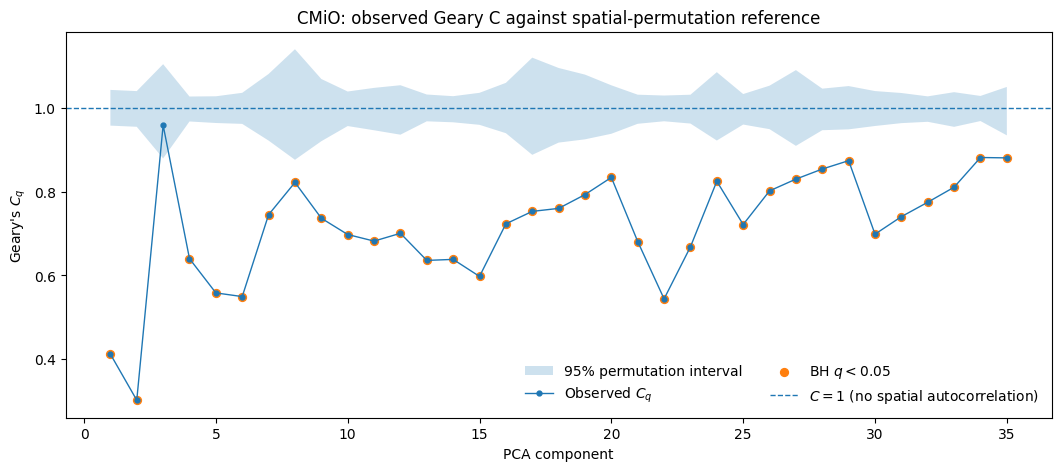

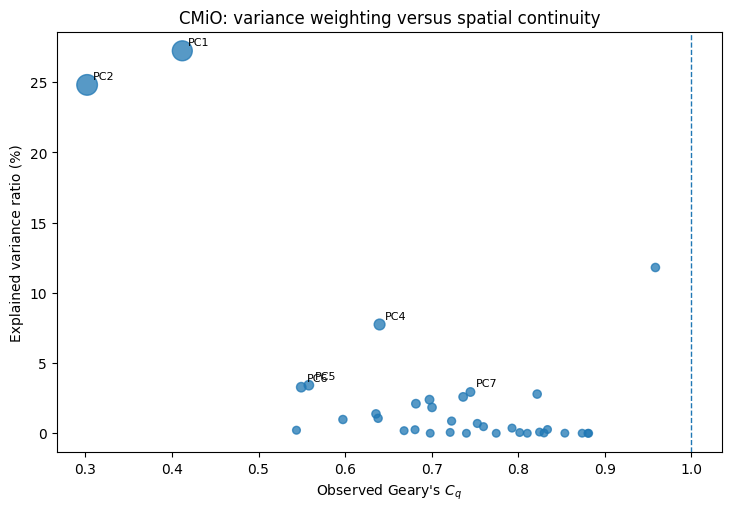

In [4]:

pc = summary['PC'].to_numpy()
lo = summary['null_C_2.5%'].to_numpy()
hi = summary['null_C_97.5%'].to_numpy()
obs = summary['observed_C'].to_numpy()
sig = summary['significant_positive_continuity'].to_numpy()

fig, ax = plt.subplots(figsize=(10.5, 4.6), constrained_layout=True)
ax.fill_between(pc, lo, hi, alpha=0.22, label='95% permutation interval')
ax.plot(pc, obs, marker='o', markersize=3.5, linewidth=1.0, label='Observed $C_q$')
ax.scatter(pc[sig], obs[sig], marker='o', s=32, label='BH $q<0.05$')
ax.axhline(1.0, linestyle='--', linewidth=1.0, label='$C=1$ (no spatial autocorrelation)')
ax.set(xlabel='PCA component', ylabel="Geary's $C_q$",
       title=f'{DATASET_NAME}: observed Geary C against spatial-permutation reference')
ax.legend(frameon=False, ncol=2)
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 5.0), constrained_layout=True)
size = 30 + 1100 * np.abs(summary['lambda_contribution'].to_numpy())
ax.scatter(summary['observed_C'], 100 * summary['explained_variance_ratio'],
           s=size, alpha=0.75)
for _, row in summary.nlargest(6, 'lambda_contribution').iterrows():
    ax.annotate(f"PC{int(row.PC)}", (row.observed_C, 100 * row.explained_variance_ratio),
                xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.axvline(1.0, linestyle='--', linewidth=1.0)
ax.set(xlabel="Observed Geary's $C_q$",
       ylabel='Explained variance ratio (%)',
       title=f'{DATASET_NAME}: variance weighting versus spatial continuity')
plt.show()



## Interpretation

The permutation keeps the PCA-score values and spatial coordinates unchanged but randomly reassigns the **rows of PCA scores to locations**. This destroys their spatial arrangement while preserving their marginal distributions and the joint PCA-score vector attached to each shuffled row. Under this null, Geary's $C$ should return toward approximately 1.

A component is flagged only when its observed $C_q$ is unusually **low** relative to the shuffled reference (positive spatial autocorrelation), with Benjamini-Hochberg correction across the PCA components. This notebook is a **diagnostic only**: it does not filter PCA components, change $\lambda$, refit SC-PaCMAP, or alter any main benchmark result.


In [5]:

sig_count = int(summary.significant_positive_continuity.sum())
print(f'{DATASET_NAME}: {sig_count}/{len(summary)} PCs have positive spatial continuity beyond the BH-adjusted permutation reference.')
print(f'Reconstructed lambda = {lambda_observed:.4f}.')
print(f'{100*contribution_fraction:.2f}% of the positive lambda contribution comes from BH-significant PCs.')

if sig_count == 0:
    print('Interpretation: the present PCA-Geary signal is not distinguishable from spatial randomization at this scale.')
elif contribution_fraction >= 0.95:
    print('Interpretation: components that materially drive lambda are supported by the permutation diagnostic; no algorithm change is required by this test.')
else:
    print('Interpretation: a material share of lambda comes from components that do not clear the permutation reference; consider a filtered sensitivity experiment before submission.')


CMiO: 34/35 PCs have positive spatial continuity beyond the BH-adjusted permutation reference.
Reconstructed lambda = 0.4571.
98.93% of the positive lambda contribution comes from BH-significant PCs.
Interpretation: components that materially drive lambda are supported by the permutation diagnostic; no algorithm change is required by this test.
